In [1]:

import os
import json
import time
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.kernel_approximation import Nystroem

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

metadata_files = [
    p for p in INPUT_DIR.rglob("metadata.json")
    if (p.parent / "X_train_scaled.npy").exists()
]

if not metadata_files:
    raise FileNotFoundError(
        "Processed dataset not found. "
        "Please add Notebook 00 output as input."
    )

DATA_DIR = metadata_files[0].parent

print("Dataset directory:", DATA_DIR)

print("\nAvailable files:")
for file in sorted(DATA_DIR.iterdir()):
    print(file.name)


Dataset directory: /kaggle/input/notebooks/ahmadlmomani/00-dry-bean-eda-preprocessing/dry_bean_processed

Available files:
X_test_scaled.csv
X_test_scaled.npy
X_train_scaled.csv
X_train_scaled.npy
imputer.pkl
label_encoder.pkl
metadata.json
scaler.pkl
y_test.csv
y_test.npy
y_train.csv
y_train.npy


In [3]:

X_train = np.load(DATA_DIR / "X_train_scaled.npy")
X_test = np.load(DATA_DIR / "X_test_scaled.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

class_names = metadata["classes"]
classes = np.unique(y_train)

print("Dataset loaded successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("Classes:", class_names)
print("Number of Classes:", len(classes))


Dataset loaded successfully!
Training Features: (10834, 16)
Testing Features: (2709, 16)
Training Labels: (10834,)
Testing Labels: (2709,)
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Number of Classes: 7


In [4]:

KERNELS = {
    "Linear": {
        "kernel": "linear"
    },
    "Polynomial": {
        "kernel": "poly",
        "degree": 3,
        "coef0": 0
    },
    "RBF": {
        "kernel": "rbf"
    },
    "Sigmoid": {
        "kernel": "sigmoid",
        "coef0": 0
    }
}

ADAM_CONFIG = {
    "learning_rate": 0.001,
    "epochs": 100,
    "beta1": 0.9,
    "beta2": 0.999,
    "epsilon": 1e-8,
    "regularization": 0.001,
    "n_components": 300
}

print("Adam Configuration:")
print(ADAM_CONFIG)

print("\nKernels:")
for name, params in KERNELS.items():
    print(name, params)


Adam Configuration:
{'learning_rate': 0.001, 'epochs': 100, 'beta1': 0.9, 'beta2': 0.999, 'epsilon': 1e-08, 'regularization': 0.001, 'n_components': 300}

Kernels:
Linear {'kernel': 'linear'}
Polynomial {'kernel': 'poly', 'degree': 3, 'coef0': 0}
RBF {'kernel': 'rbf'}
Sigmoid {'kernel': 'sigmoid', 'coef0': 0}


In [5]:

def train_svm_adam(
    X,
    y,
    learning_rate=0.001,
    epochs=100,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8,
    reg_strength=0.001
):
    n_samples, n_features = X.shape

    classes = np.unique(y)
    n_classes = len(classes)

    # One-vs-Rest labels
    Y = np.where(
        y[:, None] == classes[None, :],
        1.0,
        -1.0
    )

    # Initialize weights
    W = np.zeros((n_features, n_classes))

    # Initialize first and second moments
    m = np.zeros_like(W)
    v = np.zeros_like(W)

    loss_history = []

    for epoch in range(1, epochs + 1):

        # Calculate decision scores
        scores = X @ W

        # Calculate hinge margins
        margins = 1 - Y * scores

        # Identify active hinge losses
        active = (margins > 0).astype(float)

        # Calculate full-batch gradient
        gradient = (
            -(X.T @ (Y * active)) / n_samples
            + reg_strength * W
        )

        # Update first moment
        m = beta1 * m + (1 - beta1) * gradient

        # Update second moment
        v = beta2 * v + (1 - beta2) * (gradient ** 2)

        # Bias correction
        m_hat = m / (1 - beta1 ** epoch)
        v_hat = v / (1 - beta2 ** epoch)

        # Adam weight update
        W -= (
            learning_rate * m_hat
            / (np.sqrt(v_hat) + epsilon)
        )

        # Calculate objective loss
        scores = X @ W
        margins = 1 - Y * scores

        hinge_loss = np.maximum(0, margins)

        epoch_loss = (
            np.mean(hinge_loss, axis=0).sum()
            + 0.5 * reg_strength * np.sum(W ** 2)
        )

        loss_history.append(epoch_loss)

        if epoch % 10 == 0:
            print(
                f"Epoch {epoch}/{epochs} "
                f"| Loss: {epoch_loss:.4f}"
            )

    return W, loss_history, classes


print("Multiclass SVM with Adam implemented successfully!")


Multiclass SVM with Adam implemented successfully!


In [6]:

adam_models = {}
adam_results = []

for kernel_name, kernel_params in KERNELS.items():

    print("\n" + "=" * 60)
    print(f"Training Adam with {kernel_name} Kernel")
    print("=" * 60)

    start_time = time.time()

    # Kernel approximation
    feature_map = Nystroem(
        n_components=ADAM_CONFIG["n_components"],
        random_state=RANDOM_STATE,
        gamma=1.0 / X_train.shape[1],
        **kernel_params
    )

    Z_train = feature_map.fit_transform(X_train)
    Z_test = feature_map.transform(X_test)

    # Train using Adam
    W, loss_history, trained_classes = train_svm_adam(
        Z_train,
        y_train,
        learning_rate=ADAM_CONFIG["learning_rate"],
        epochs=ADAM_CONFIG["epochs"],
        beta1=ADAM_CONFIG["beta1"],
        beta2=ADAM_CONFIG["beta2"],
        epsilon=ADAM_CONFIG["epsilon"],
        reg_strength=ADAM_CONFIG["regularization"]
    )

    # Predictions
    test_scores = Z_test @ W

    y_pred = trained_classes[
        np.argmax(test_scores, axis=1)
    ]

    training_time = time.time() - start_time

    # Store model
    adam_models[kernel_name] = {
        "feature_map": feature_map,
        "weights": W,
        "classes": trained_classes,
        "loss_history": loss_history
    }

    # Evaluation
    adam_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Final Loss": loss_history[-1],
        "Training Time": training_time
    })

    print(f"\n{kernel_name} completed!")
    print(f"Final Loss: {loss_history[-1]:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll Adam experiments completed!")



Training Adam with Linear Kernel
Epoch 10/100 | Loss: 6.2186
Epoch 20/100 | Loss: 5.6913
Epoch 30/100 | Loss: 5.5433
Epoch 40/100 | Loss: 5.4490
Epoch 50/100 | Loss: 5.3868
Epoch 60/100 | Loss: 5.3403
Epoch 70/100 | Loss: 5.2971
Epoch 80/100 | Loss: 5.2548
Epoch 90/100 | Loss: 5.2135
Epoch 100/100 | Loss: 5.1726

Linear completed!
Final Loss: 5.1726
Training Time: 1.71 seconds

Training Adam with Polynomial Kernel
Epoch 10/100 | Loss: 6.7125
Epoch 20/100 | Loss: 6.4950
Epoch 30/100 | Loss: 6.3379
Epoch 40/100 | Loss: 6.1993
Epoch 50/100 | Loss: 6.0729
Epoch 60/100 | Loss: 5.9580
Epoch 70/100 | Loss: 5.8535
Epoch 80/100 | Loss: 5.7581
Epoch 90/100 | Loss: 5.6705
Epoch 100/100 | Loss: 5.5891

Polynomial completed!
Final Loss: 5.5891
Training Time: 1.72 seconds

Training Adam with RBF Kernel
Epoch 10/100 | Loss: 6.4962
Epoch 20/100 | Loss: 5.9926
Epoch 30/100 | Loss: 5.4892
Epoch 40/100 | Loss: 4.9862
Epoch 50/100 | Loss: 4.4835
Epoch 60/100 | Loss: 3.9811
Epoch 70/100 | Loss: 3.4790
Epo

In [7]:

adam_results_df = pd.DataFrame(adam_results)

adam_results_df = adam_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("Adam Results")

display(
    adam_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Final Loss": "{:.4f}",
        "Training Time": "{:.2f}"
    })
)


Adam Results


,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Final Loss,Training Time
0,Linear,0.8121,0.7982,0.8351,0.8008,0.8047,5.1726,1.71
1,RBF,0.7202,0.7156,0.7508,0.7151,0.6479,2.3880,1.60
2,Polynomial,0.7135,0.7691,0.7700,0.7047,0.6708,5.5891,1.72
3,Sigmoid,0.5855,0.6978,0.5149,0.4761,0.5047,5.0003,1.89


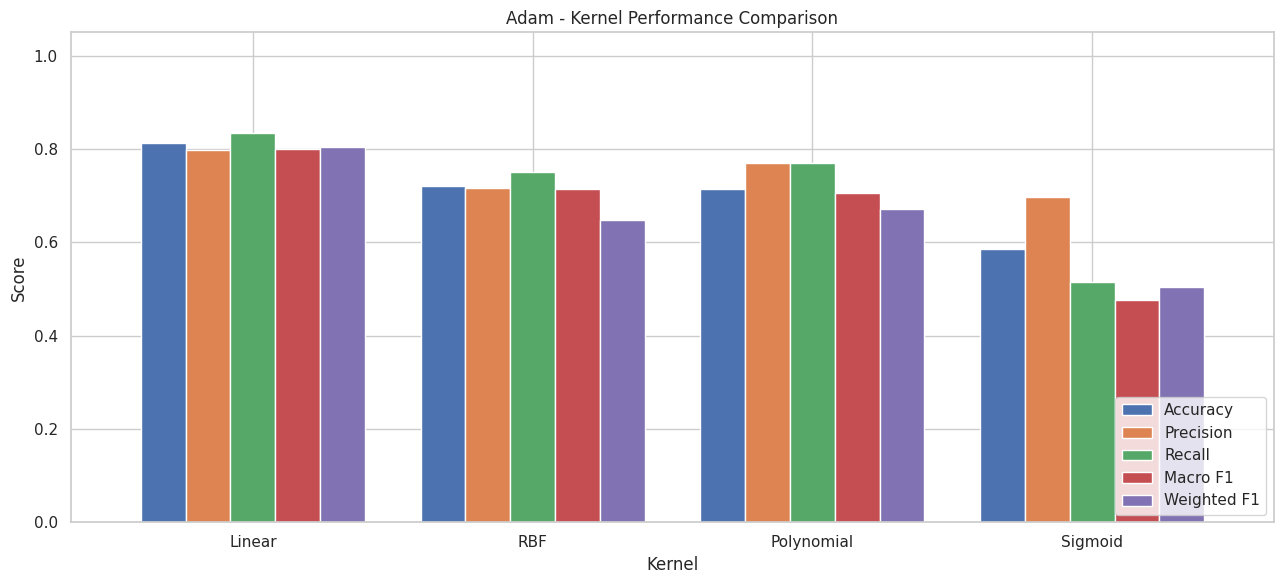

In [8]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1"
]

adam_plot = adam_results_df.set_index("Kernel")[metrics]

adam_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Adam - Kernel Performance Comparison")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


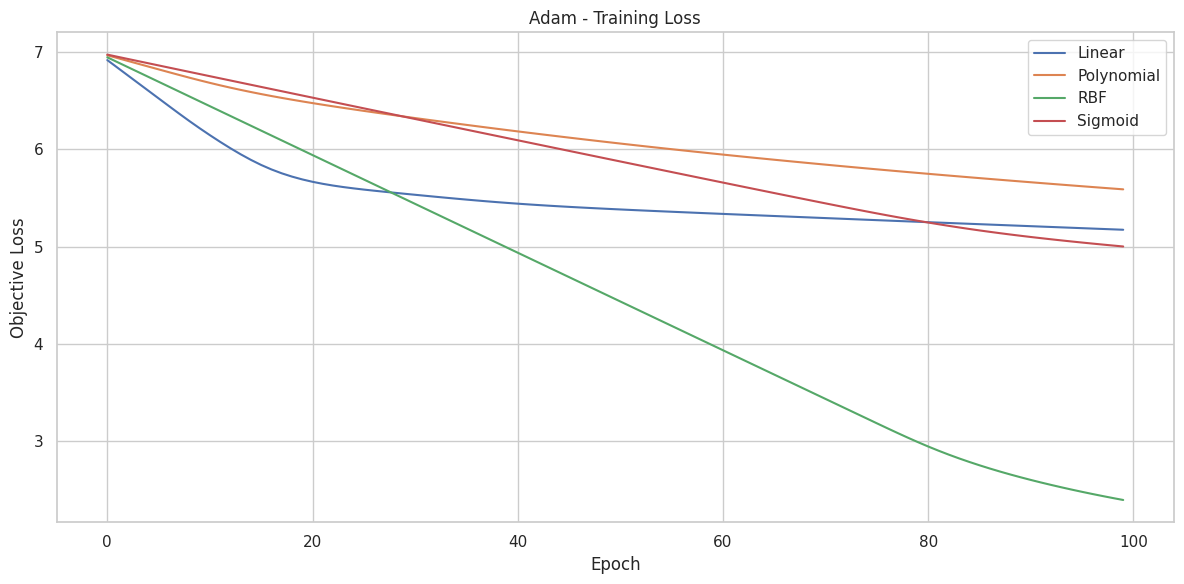

In [9]:

plt.figure(figsize=(12, 6))

for kernel_name, model_data in adam_models.items():

    plt.plot(
        model_data["loss_history"],
        label=kernel_name
    )

plt.title("Adam - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Objective Loss")

plt.legend()
plt.tight_layout()
plt.show()


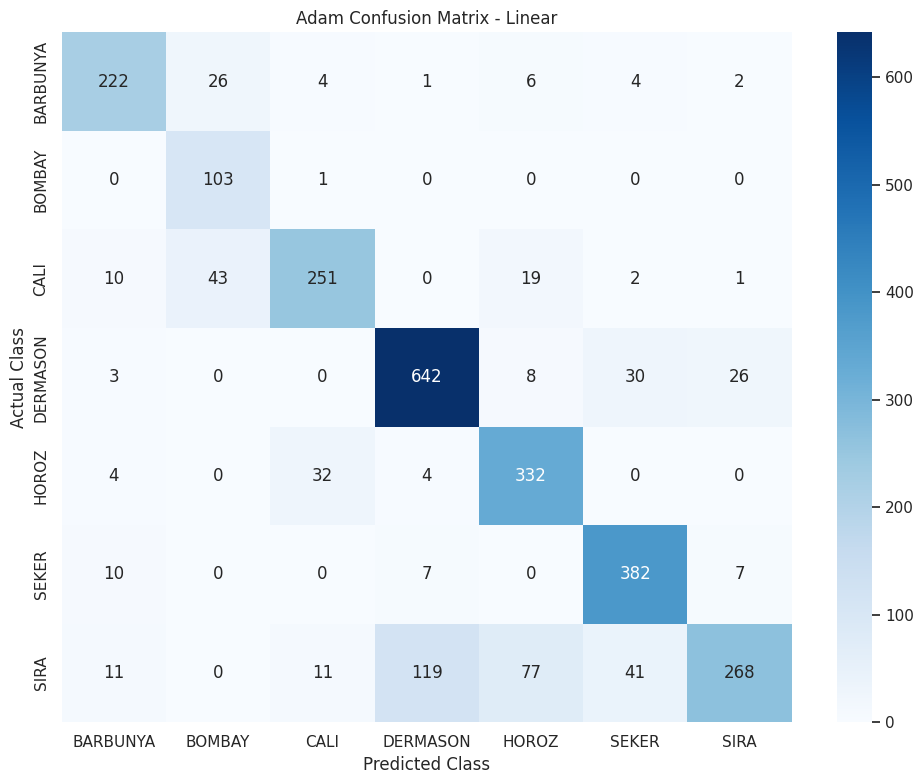

Best Kernel: Linear


In [10]:

best_kernel = adam_results_df.iloc[0]["Kernel"]

best_model = adam_models[best_kernel]

Z_test_best = best_model["feature_map"].transform(X_test)

y_pred = best_model["classes"][
    np.argmax(
        Z_test_best @ best_model["weights"],
        axis=1
    )
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"Adam Confusion Matrix - {best_kernel}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Best Kernel:", best_kernel)


In [11]:

print(
    f"Classification Report - Adam with {best_kernel} Kernel"
)

print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        target_names=class_names,
        zero_division=0
    )
)


Classification Report - Adam with Linear Kernel
              precision    recall  f1-score   support

    BARBUNYA       0.85      0.84      0.85       265
      BOMBAY       0.60      0.99      0.75       104
        CALI       0.84      0.77      0.80       326
    DERMASON       0.83      0.91      0.87       709
       HOROZ       0.75      0.89      0.82       372
       SEKER       0.83      0.94      0.88       406
        SIRA       0.88      0.51      0.65       527

    accuracy                           0.81      2709
   macro avg       0.80      0.84      0.80      2709
weighted avg       0.82      0.81      0.80      2709



In [12]:

OUTPUT_DIR = Path("/kaggle/working/adam_results")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison table
adam_results_df.to_csv(
    OUTPUT_DIR / "adam_comparison.csv",
    index=False
)

# Save trained models
joblib.dump(
    adam_models,
    OUTPUT_DIR / "adam_models.pkl"
)

# Save predictions for all kernels
predictions = {}

for kernel_name, model_data in adam_models.items():

    Z_test = model_data["feature_map"].transform(X_test)

    scores = Z_test @ model_data["weights"]

    predictions[kernel_name] = model_data["classes"][
        np.argmax(scores, axis=1)
    ]

predictions_df = pd.DataFrame({
    "Actual": y_test
})

for kernel_name, pred in predictions.items():
    predictions_df[kernel_name] = pred

predictions_df.to_csv(
    OUTPUT_DIR / "adam_predictions.csv",
    index=False
)

# Save configuration
config = {
    "optimizer": "Adam",
    "learning_rate": ADAM_CONFIG["learning_rate"],
    "epochs": ADAM_CONFIG["epochs"],
    "beta1": ADAM_CONFIG["beta1"],
    "beta2": ADAM_CONFIG["beta2"],
    "epsilon": ADAM_CONFIG["epsilon"],
    "regularization": ADAM_CONFIG["regularization"],
    "n_components": ADAM_CONFIG["n_components"],
    "kernels": list(KERNELS.keys()),
    "random_state": RANDOM_STATE,
    "classes": class_names
}

with open(OUTPUT_DIR / "adam_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Adam results saved successfully!")

print("\nSaved files:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


Adam results saved successfully!

Saved files:
adam_predictions.csv
adam_comparison.csv
adam_config.json
adam_models.pkl
